In [ ]:
print("Satellite Image Change Detection Project")
print("Google Colab is working successfully!")

Satellite Image Change Detection Project
Google Colab is working successfully!


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cu130
GPU available: True


In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

path = '/content/drive/MyDrive'

print("My Drive folders:")

for folder in os.listdir(path):
    print(folder)

My Drive folders:
Gowthami S 20241CSE0594 2PHY10 ( Mechanical notes)
Colab Notebooks
Adhar pd.pdf
give all the questions ans.gsheet
city_graph.gdoc
Admit-Card_20241CAI0154_2026-05-06_14-02-15_copy.pdf
Stock_Price_Predicition.pdf
Fake_News_Detection_Report (3) (1).pdf
Fake_News_Detection_Report (3).pdf
DocScanner 4 Jul 2026 18-19.pdf
NOC26GE105S752104419 (1).pdf
NOC26GE105S752104419 (2) (1).pdf
NOC26GE105S752104419 (2).pdf
Untitled spreadsheet.gsheet
LEVIR-CD


In [3]:
dataset_path = '/content/drive/MyDrive/LEVIR-CD'

print("Dataset contents:")

for item in os.listdir(dataset_path):
    print(item)

Dataset contents:
val.zip
train.zip
test.zip
PAM-pretrain
BIT_LEVIR


In [4]:
import os

base_path = '/content/drive/MyDrive/LEVIR-CD'

extract_path = '/content/LEVIR_dataset'

os.makedirs(extract_path, exist_ok=True)

print("Dataset folder created successfully!")

Dataset folder created successfully!


In [5]:
import zipfile

train_zip = os.path.join(base_path, 'train.zip')

with zipfile.ZipFile(train_zip, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Training dataset extracted successfully!")

Training dataset extracted successfully!


In [6]:
for root, dirs, files in os.walk(extract_path):
    print("Folder:", root)
    print("Subfolders:", dirs)
    print("Number of files:", len(files))
    print("-------------------")

Folder: /content/LEVIR_dataset
Subfolders: ['A', 'label', 'B']
Number of files: 0
-------------------
Folder: /content/LEVIR_dataset/A
Subfolders: []
Number of files: 445
-------------------
Folder: /content/LEVIR_dataset/label
Subfolders: []
Number of files: 445
-------------------
Folder: /content/LEVIR_dataset/B
Subfolders: []
Number of files: 445
-------------------


In [7]:
import os

extract_path = '/content/LEVIR_dataset'

for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:5]:
            print("  " * (level + 1) + file)

        if len(files) > 5:
            print("  " * (level + 1) + "...")

LEVIR_dataset/
  A/
    train_211.png
    train_140.png
    train_66.png
    train_424.png
    train_128.png
    ...
  label/
    train_211.png
    train_140.png
    train_66.png
    train_424.png
    train_128.png
    ...
  B/
    train_211.png
    train_140.png
    train_66.png
    train_424.png
    train_128.png
    ...


In [8]:
import os
import matplotlib.pyplot as plt
from PIL import Image

base_path = '/content/LEVIR_dataset'

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
image_name = 'train_211.png'

img_A = Image.open(
    os.path.join(base_path, 'A', image_name)
)

img_B = Image.open(
    os.path.join(base_path, 'B', image_name)
)

mask = Image.open(
    os.path.join(base_path, 'label', image_name)
)

print("Image A size:", img_A.size)
print("Image B size:", img_B.size)
print("Mask size:", mask.size)

Image A size: (1024, 1024)
Image B size: (1024, 1024)
Mask size: (1024, 1024)


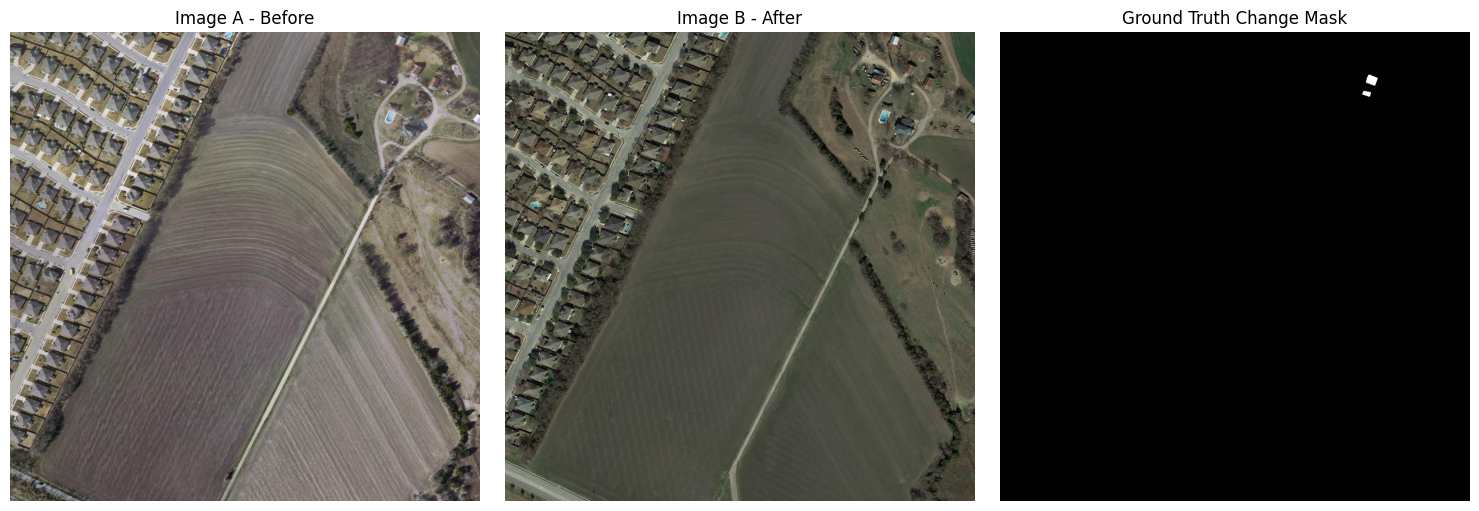

In [10]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_A)
plt.title("Image A - Before")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_B)
plt.title("Image B - After")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(mask, cmap='gray')
plt.title("Ground Truth Change Mask")
plt.axis('off')

plt.tight_layout()
plt.show()

In [11]:
import os
import numpy as np
from PIL import Image

base_path = '/content/LEVIR_dataset'

print("Dataset analysis started!")

Dataset analysis started!


In [12]:
folders = ['A', 'B', 'label']

for folder in folders:
    folder_path = os.path.join(base_path, folder)

    files = [
        f for f in os.listdir(folder_path)
        if f.endswith('.png')
    ]

    print(folder, ":", len(files), "images")

A : 445 images
B : 445 images
label : 445 images


In [13]:
image_name = 'train_211.png'

for folder in folders:
    path = os.path.join(base_path, folder, image_name)

    img = Image.open(path)

    print(folder, "Image size:", img.size)
    print(folder, "Image mode:", img.mode)

A Image size: (1024, 1024)
A Image mode: RGB
B Image size: (1024, 1024)
B Image mode: RGB
label Image size: (1024, 1024)
label Image mode: L


In [14]:
mask_path = os.path.join(
    base_path, 'label', 'train_211.png'
)

mask = np.array(Image.open(mask_path))

print("Unique mask pixel values:")
print(np.unique(mask))

print("Minimum pixel value:", mask.min())
print("Maximum pixel value:", mask.max())

Unique mask pixel values:
[  0 255]
Minimum pixel value: 0
Maximum pixel value: 255


In [15]:
import os

A_path = '/content/LEVIR_dataset/A'
B_path = '/content/LEVIR_dataset/B'
label_path = '/content/LEVIR_dataset/label'

A_files = set(os.listdir(A_path))
B_files = set(os.listdir(B_path))
label_files = set(os.listdir(label_path))

print("Images in A:", len(A_files))
print("Images in B:", len(B_files))
print("Labels:", len(label_files))

print("\nMatching filenames:",
      len(A_files & B_files & label_files))

print("Missing in B:", len(A_files - B_files))
print("Missing labels:", len(A_files - label_files))

Images in A: 445
Images in B: 445
Labels: 445

Matching filenames: 445
Missing in B: 0
Missing labels: 0


In [16]:
import zipfile
import os

base_path = '/content/drive/MyDrive/LEVIR-CD'

for filename in ['val.zip', 'test.zip']:

    zip_path = os.path.join(base_path, filename)

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:

        files = zip_ref.namelist()

        print("\n", filename)
        print("Total entries:", len(files))
        print("First 10 entries:")

        for item in files[:10]:
            print(item)


 val.zip
Total entries: 195
First 10 entries:
A/
A/val_1.png
A/val_10.png
A/val_11.png
A/val_12.png
A/val_13.png
A/val_14.png
A/val_15.png
A/val_16.png
A/val_17.png

 test.zip
Total entries: 387
First 10 entries:
A/
A/test_1.png
A/test_10.png
A/test_100.png
A/test_101.png
A/test_102.png
A/test_103.png
A/test_104.png
A/test_105.png
A/test_106.png


In [17]:
import os
import zipfile

drive_path = '/content/drive/MyDrive/LEVIR-CD'

val_zip = os.path.join(drive_path, 'val.zip')
test_zip = os.path.join(drive_path, 'test.zip')

val_path = '/content/LEVIR_val'
test_path = '/content/LEVIR_test'

os.makedirs(val_path, exist_ok=True)
os.makedirs(test_path, exist_ok=True)

print("Validation and testing folders created!")

Validation and testing folders created!


In [18]:
with zipfile.ZipFile(val_zip, 'r') as zip_ref:
    zip_ref.extractall(val_path)

print("Validation dataset extracted successfully!")

Validation dataset extracted successfully!


In [19]:
with zipfile.ZipFile(test_zip, 'r') as zip_ref:
    zip_ref.extractall(test_path)

print("Testing dataset extracted successfully!")

Testing dataset extracted successfully!


In [20]:
datasets = {
    "Training": "/content/LEVIR_dataset",
    "Validation": "/content/LEVIR_val",
    "Testing": "/content/LEVIR_test"
}

for name, path in datasets.items():

    print("\n", name)

    for folder in ["A", "B", "label"]:

        folder_path = os.path.join(path, folder)

        files = [
            f for f in os.listdir(folder_path)
            if f.endswith(".png")
        ]

        print(folder, ":", len(files), "images")


 Training
A : 445 images
B : 445 images
label : 445 images

 Validation
A : 64 images
B : 64 images
label : 64 images

 Testing
A : 128 images
B : 128 images
label : 128 images


In [21]:
import torch
import torchvision
import numpy as np
import os

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
GPU available: True


In [22]:
class LEVIRDataset(Dataset):

    def __init__(self, root_dir):

        self.root_dir = root_dir

        self.A_dir = os.path.join(root_dir, 'A')
        self.B_dir = os.path.join(root_dir, 'B')
        self.label_dir = os.path.join(root_dir, 'label')

        self.image_names = sorted([
            f for f in os.listdir(self.A_dir)
            if f.endswith('.png')
        ])

        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.5, 0.5, 0.5],
                std=[0.5, 0.5, 0.5]
            )
        ])

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, idx):

        image_name = self.image_names[idx]

        img_A = Image.open(
            os.path.join(self.A_dir, image_name)
        ).convert('RGB')

        img_B = Image.open(
            os.path.join(self.B_dir, image_name)
        ).convert('RGB')

        mask = Image.open(
            os.path.join(self.label_dir, image_name)
        ).convert('L')

        img_A = self.transform(img_A)
        img_B = self.transform(img_B)

        mask = transforms.ToTensor()(mask)
        mask = (mask > 0).float()

        return img_A, img_B, mask

In [23]:
train_dataset = LEVIRDataset(
    '/content/LEVIR_dataset'
)

val_dataset = LEVIRDataset(
    '/content/LEVIR_val'
)

test_dataset = LEVIRDataset(
    '/content/LEVIR_test'
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Training images: 445
Validation images: 64
Testing images: 128


In [24]:
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [25]:
images_A, images_B, masks = next(iter(train_loader))

print("Image A shape:", images_A.shape)
print("Image B shape:", images_B.shape)
print("Mask shape:", masks.shape)

Image A shape: torch.Size([4, 3, 1024, 1024])
Image B shape: torch.Size([4, 3, 1024, 1024])
Mask shape: torch.Size([4, 1, 1024, 1024])


In [26]:
class LEVIRDataset(Dataset):

    def __init__(self, root_dir):

        self.root_dir = root_dir

        self.A_dir = os.path.join(root_dir, 'A')
        self.B_dir = os.path.join(root_dir, 'B')
        self.label_dir = os.path.join(root_dir, 'label')

        self.image_names = sorted([
            f for f in os.listdir(self.A_dir)
            if f.endswith('.png')
        ])

        self.image_transform = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.5, 0.5, 0.5],
                std=[0.5, 0.5, 0.5]
            )
        ])

        self.mask_transform = transforms.Compose([
            transforms.Resize(
                (256, 256),
                interpolation=transforms.InterpolationMode.NEAREST
            ),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, idx):

        image_name = self.image_names[idx]

        img_A = Image.open(
            os.path.join(self.A_dir, image_name)
        ).convert('RGB')

        img_B = Image.open(
            os.path.join(self.B_dir, image_name)
        ).convert('RGB')

        mask = Image.open(
            os.path.join(self.label_dir, image_name)
        ).convert('L')

        img_A = self.image_transform(img_A)
        img_B = self.image_transform(img_B)

        mask = self.mask_transform(mask)
        mask = (mask > 0.5).float()

        return img_A, img_B, mask


print("Updated LEVIR Dataset class successfully!")

Updated LEVIR Dataset class successfully!


In [27]:
train_dataset = LEVIRDataset('/content/LEVIR_dataset')

val_dataset = LEVIRDataset('/content/LEVIR_val')

test_dataset = LEVIRDataset('/content/LEVIR_test')

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 445
Validation: 64
Testing: 128


In [28]:
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

print("New DataLoaders created!")

New DataLoaders created!


In [29]:
images_A, images_B, masks = next(iter(train_loader))

print("Image A:", images_A.shape)
print("Image B:", images_B.shape)
print("Mask:", masks.shape)

Image A: torch.Size([4, 3, 256, 256])
Image B: torch.Size([4, 3, 256, 256])
Mask: torch.Size([4, 1, 256, 256])


In [30]:
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print("Using device:", device)

Using device: cuda


In [31]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

In [36]:
class SiameseUNet(nn.Module):

    def __init__(self):

        super().__init__()

        # Shared encoder
        self.enc1 = ConvBlock(3, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.enc4 = ConvBlock(128, 256)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ConvBlock(256, 512)

        # Decoder
        self.dec4 = ConvBlock(512+256, 256)
        self.dec3 = ConvBlock(256+128, 128)
        self.dec2 = ConvBlock(128+64, 64)
        self.dec1 = ConvBlock(64+32, 32)
        # Output
        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, img1, img2):

        # Encode first image
        x1 = self.enc1(img1)
        x2 = self.enc2(self.pool(x1))
        x3 = self.enc3(self.pool(x2))
        x4 = self.enc4(self.pool(x3))

        # Encode second image using shared weights
        y1 = self.enc1(img2)
        y2 = self.enc2(self.pool(y1))
        y3 = self.enc3(self.pool(y2))
        y4 = self.enc4(self.pool(y3))

        # Calculate absolute feature differences
        d1 = torch.abs(x1 - y1)
        d2 = torch.abs(x2 - y2)
        d3 = torch.abs(x3 - y3)
        d4 = torch.abs(x4 - y4)

        # Bottleneck
        z = self.bottleneck(
            self.pool(d4)
        )

        # Decoder
        z = F.interpolate(
            z, size=d4.shape[2:],
            mode='bilinear', align_corners=False
        )
        z = self.dec4(torch.cat([z, d4], dim=1))

        z = F.interpolate(
            z, size=d3.shape[2:],
            mode='bilinear', align_corners=False
        )
        z = self.dec3(torch.cat([z, d3], dim=1))

        z = F.interpolate(
            z, size=d2.shape[2:],
            mode='bilinear', align_corners=False
        )
        z = self.dec2(torch.cat([z, d2], dim=1))

        z = F.interpolate(
            z, size=d1.shape[2:],
            mode='bilinear', align_corners=False
        )
        z = self.dec1(torch.cat([z, d1], dim=1))

        return self.output(z)

In [37]:
model = SiameseUNet().to(device)

print(model)

SiameseUNet(
  (enc1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc3): ConvBlock(
    (block): Sequen

In [38]:
images_A, images_B, masks = next(iter(train_loader))

images_A = images_A.to(device)
images_B = images_B.to(device)

model.eval()

with torch.no_grad():

    predictions = model(images_A, images_B)

print("Image A:", images_A.shape)
print("Image B:", images_B.shape)
print("Predictions:", predictions.shape)

Image A: torch.Size([4, 3, 256, 256])
Image B: torch.Size([4, 3, 256, 256])
Predictions: torch.Size([4, 1, 256, 256])


In [39]:
import torch.optim as optim

# Loss function
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.0001)

print("Loss function and optimizer are ready!")

Loss function and optimizer are ready!


In [40]:
num_epochs = 10

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for images_A, images_B, masks in train_loader:
        images_A = images_A.to(device)
        images_B = images_B.to(device)
        masks = masks.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images_A, images_B)

        # Calculate loss
        loss = criterion(outputs, masks)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}")

Epoch [1/10], Loss: 0.4799
Epoch [2/10], Loss: 0.3688
Epoch [3/10], Loss: 0.3269
Epoch [4/10], Loss: 0.2902
Epoch [5/10], Loss: 0.2615
Epoch [6/10], Loss: 0.2366
Epoch [7/10], Loss: 0.2170
Epoch [8/10], Loss: 0.1981
Epoch [9/10], Loss: 0.1812
Epoch [10/10], Loss: 0.1663


In [41]:
model.eval()
val_loss = 0.0

with torch.no_grad():
    for images_A, images_B, masks in val_loader:
        images_A = images_A.to(device)
        images_B = images_B.to(device)
        masks = masks.to(device)

        outputs = model(images_A, images_B)
        loss = criterion(outputs, masks)

        val_loss += loss.item()

val_loss = val_loss / len(val_loader)

print(f"Validation Loss: {val_loss:.4f}")

Validation Loss: 0.1678


In [42]:
from sklearn.metrics import precision_score, recall_score, f1_score

model.eval()

all_predictions = []
all_masks = []

with torch.no_grad():
    for images_A, images_B, masks in test_loader:
        images_A = images_A.to(device)
        images_B = images_B.to(device)

        outputs = model(images_A, images_B)

        # Convert logits into binary predictions
        predictions = (torch.sigmoid(outputs) > 0.5).cpu().numpy()
        masks = masks.numpy()

        all_predictions.extend(predictions.reshape(-1))
        all_masks.extend(masks.reshape(-1))

precision = precision_score(all_masks, all_predictions, zero_division=0)
recall = recall_score(all_masks, all_predictions, zero_division=0)
f1 = f1_score(all_masks, all_predictions, zero_division=0)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

Precision: 0.8664
Recall: 0.2964
F1 Score: 0.4417


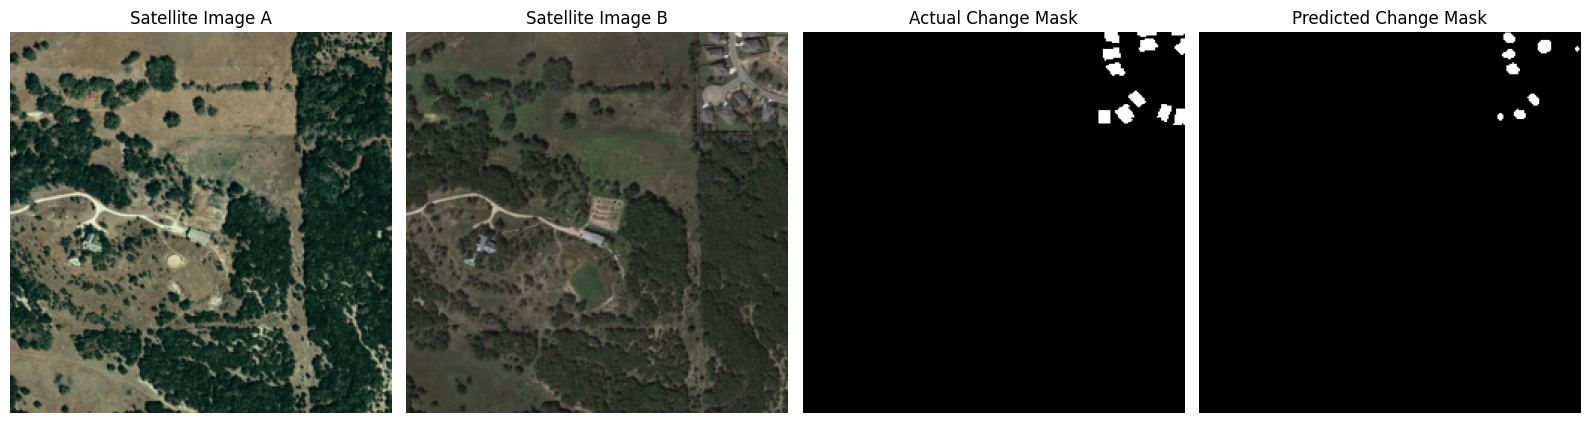

In [43]:
import matplotlib.pyplot as plt

model.eval()

images_A, images_B, masks = next(iter(test_loader))

images_A = images_A.to(device)
images_B = images_B.to(device)

with torch.no_grad():
    outputs = model(images_A, images_B)
    predictions = (torch.sigmoid(outputs) > 0.5).float()

# Display the first sample
img_A = images_A[0].cpu().permute(1, 2, 0)
img_B = images_B[0].cpu().permute(1, 2, 0)

# Undo normalization
img_A = img_A * 0.5 + 0.5
img_B = img_B * 0.5 + 0.5

actual_mask = masks[0, 0].cpu()
predicted_mask = predictions[0, 0].cpu()

plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(img_A)
plt.title("Satellite Image A")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(img_B)
plt.title("Satellite Image B")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(actual_mask, cmap="gray")
plt.title("Actual Change Mask")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(predicted_mask, cmap="gray")
plt.title("Predicted Change Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [44]:
total_pixels = 0
changed_pixels = 0

for images_A, images_B, masks in train_loader:
    changed_pixels += masks.sum().item()
    total_pixels += masks.numel()

unchanged_pixels = total_pixels - changed_pixels

print("Changed pixels:", int(changed_pixels))
print("Unchanged pixels:", int(unchanged_pixels))
print("Changed pixel percentage:",
      round(100 * changed_pixels / total_pixels, 2), "%")

Changed pixels: 1338323
Unchanged pixels: 27825197
Changed pixel percentage: 4.59 %


In [45]:
# Calculate the class weight
pos_weight = torch.tensor(
    [unchanged_pixels / changed_pixels],
    dtype=torch.float32
).to(device)

# Weighted loss function
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Reset the model so it trains with the new loss
model = SiameseUNet().to(device)

# Create a fresh optimizer
optimizer = optim.Adam(model.parameters(), lr=0.0001)

print("Positive class weight:", pos_weight.item())
print("Weighted loss function is ready!")

Positive class weight: 20.791091918945312
Weighted loss function is ready!


In [46]:
num_epochs = 10

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for images_A, images_B, masks in train_loader:
        images_A = images_A.to(device)
        images_B = images_B.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images_A, images_B)

        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}], "
        f"Loss: {epoch_loss:.4f}"
    )

Epoch [1/10], Loss: 0.8114
Epoch [2/10], Loss: 0.5700
Epoch [3/10], Loss: 0.5025
Epoch [4/10], Loss: 0.4457
Epoch [5/10], Loss: 0.3937
Epoch [6/10], Loss: 0.3674
Epoch [7/10], Loss: 0.3461
Epoch [8/10], Loss: 0.3099
Epoch [9/10], Loss: 0.2838
Epoch [10/10], Loss: 0.3168


In [47]:
from sklearn.metrics import precision_score, recall_score, f1_score

model.eval()

all_predictions = []
all_masks = []

with torch.no_grad():
    for images_A, images_B, masks in val_loader:
        images_A = images_A.to(device)
        images_B = images_B.to(device)

        outputs = model(images_A, images_B)

        predictions = (torch.sigmoid(outputs) > 0.5).cpu().numpy()

        all_predictions.extend(predictions.reshape(-1))
        all_masks.extend(masks.numpy().reshape(-1))

precision = precision_score(
    all_masks, all_predictions, zero_division=0
)

recall = recall_score(
    all_masks, all_predictions, zero_division=0
)

f1 = f1_score(
    all_masks, all_predictions, zero_division=0
)

print(f"Validation Precision: {precision:.4f}")
print(f"Validation Recall: {recall:.4f}")
print(f"Validation F1 Score: {f1:.4f}")

Validation Precision: 0.5150
Validation Recall: 0.8558
Validation F1 Score: 0.6430


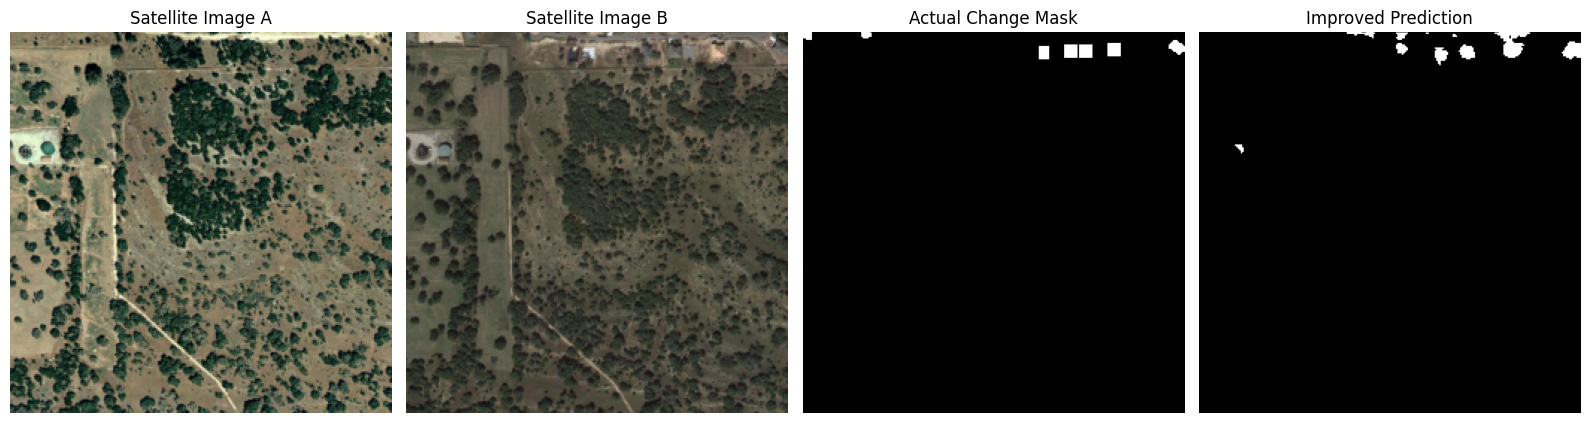

In [48]:
import matplotlib.pyplot as plt

model.eval()

images_A, images_B, masks = next(iter(val_loader))

images_A = images_A.to(device)
images_B = images_B.to(device)

with torch.no_grad():
    outputs = model(images_A, images_B)
    predictions = (torch.sigmoid(outputs) > 0.5).float()

img_A = images_A[0].cpu().permute(1, 2, 0) * 0.5 + 0.5
img_B = images_B[0].cpu().permute(1, 2, 0) * 0.5 + 0.5

actual_mask = masks[0, 0].cpu()
predicted_mask = predictions[0, 0].cpu()

plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(img_A)
plt.title("Satellite Image A")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(img_B)
plt.title("Satellite Image B")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(actual_mask, cmap="gray")
plt.title("Actual Change Mask")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(predicted_mask, cmap="gray")
plt.title("Improved Prediction")
plt.axis("off")

plt.tight_layout()
plt.show()

In [49]:
from sklearn.metrics import precision_score, recall_score, f1_score

model.eval()

all_predictions = []
all_masks = []

with torch.no_grad():
    for images_A, images_B, masks in test_loader:
        images_A = images_A.to(device)
        images_B = images_B.to(device)

        outputs = model(images_A, images_B)

        predictions = (
            torch.sigmoid(outputs) > 0.5
        ).cpu().numpy()

        all_predictions.extend(predictions.reshape(-1))
        all_masks.extend(masks.numpy().reshape(-1))

test_precision = precision_score(
    all_masks, all_predictions, zero_division=0
)

test_recall = recall_score(
    all_masks, all_predictions, zero_division=0
)

test_f1 = f1_score(
    all_masks, all_predictions, zero_division=0
)

print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
print(f"Test F1 Score: {test_f1:.4f}")

Test Precision: 0.5360
Test Recall: 0.8145
Test F1 Score: 0.6465


In [50]:
import os
import torch

# Create project folder in Google Drive
save_dir = "/content/drive/MyDrive/satellite-image-change-detection"
os.makedirs(save_dir, exist_ok=True)

# Save trained model and configuration
save_path = os.path.join(
    save_dir,
    "siamese_unet_weighted.pth"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "test_precision": test_precision,
    "test_recall": test_recall,
    "test_f1": test_f1,
    "epochs": 10
}, save_path)

print("Model saved successfully!")
print("Location:", save_path)

Model saved successfully!
Location: /content/drive/MyDrive/satellite-image-change-detection/siamese_unet_weighted.pth


In [51]:
readme_content = """
# Satellite Image Change Detection Using Deep Learning

## 1. Project Overview

This project uses deep learning to identify changes between two
satellite images of the same geographical area taken at different times.

A Siamese U-Net architecture is used to generate a binary change mask.

## 2. Dataset

Dataset: LEVIR-CD

Official source:
https://justchenhao.github.io/LEVIR/

The dataset contains:
- Image A: Earlier satellite image
- Image B: Later satellite image
- Label: Ground-truth change mask

The dataset is not included in this repository.

## 3. Model Architecture

Model: Siamese U-Net

- Shared convolutional encoder
- Feature difference using absolute subtraction
- U-Net-style decoder
- Binary change prediction output

## 4. Training Configuration

- Framework: PyTorch
- Input image size: 256 x 256
- Batch size: 4
- Epochs: 10
- Optimizer: Adam
- Learning rate: 0.0001
- Loss function: Weighted Binary Cross Entropy with Logits

## 5. Final Test Results

| Metric | Score |
|---|---:|
| Precision | 0.5360 |
| Recall | 0.8145 |
| F1-score | 0.6465 |

## 6. Technologies Used

- Python
- PyTorch
- Google Colab
- NumPy
- Matplotlib
- Scikit-learn

## 7. Project Structure

satellite-image-change-detection/
├── README.md
├── Satellite_Change_Detection.ipynb
└── siamese_unet_weighted.pth

Note: The trained model file and notebook can be added separately.
The LEVIR-CD dataset should not be uploaded to GitHub.

## 8. Conclusion

The project demonstrates satellite image change detection using
a Siamese U-Net deep learning model.

The weighted loss function helps address class imbalance and
improves the detection of changed pixels.
"""

readme_path = os.path.join(save_dir, "README.md")

with open(readme_path, "w") as file:
    file.write(readme_content)

print("README.md created successfully!")
print("Location:", readme_path)

README.md created successfully!
Location: /content/drive/MyDrive/satellite-image-change-detection/README.md
